# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [ ]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Потапова Світлана'
GROUP        = 'ШІ-31'
NUMBER       = 16

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Потапова Світлана | ШІ-31 | номер 16


In [ ]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 16   ·   Потапова Світлана   ·   ШІ-31

   Ринок:  Kherson
   Товар:  сир кисломолочний   (у наборі даних: Curd - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [ ]:
# Завдання 1. Підготовка ряду

import pandas as pd

df = pd.read_csv('ціни_україна_2014_2017.csv')

df['date'] = pd.to_datetime(
    df['рік'].astype(str) + '-' + df['місяць'].astype(str) + '-01'
)

ts_data = df[(df['ринок'] == MARKET) & (df['товар'] == GOOD)].copy()

full_idx = pd.date_range(start='2014-03-01', end='2017-12-01', freq='MS')

ts_data = ts_data.set_index('date').reindex(full_idx)
ts_data.index.name = 'date'

total_months = len(ts_data)
measured_months = ts_data['ціна'].count()
missing_dates = ts_data[ts_data['ціна'].isna()].index

print(f"1. Всього місяців у сітці: {total_months}")
print(f"   Місяців із вимірами: {measured_months}")
print(f"2. Дата пропуску: {missing_dates[0].strftime('%Y-%m')}")
print(f"3. Кількість знайдених пропусків: {len(missing_dates)}")



1. Всього місяців у сітці: 46
   Місяців із вимірами: 45
2. Дата пропуску: 2017-08
3. Кількість знайдених пропусків: 1


**Висновок до завдання 1:**

Сітка за період 03.2014-12.2017 містить 46 місяців, з них виміри мають 45.

Пропуск виявлено у серпні 2017 року. Причиною пропуску може бути людський або технічний чинник (не зібрано дані або не внесено їх до реєстру)

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [ ]:
# Завдання 2. Заповнення пропуску

val_ffill = ts_data['ціна'].ffill().loc['2017-08-01']
val_linear = ts_data['ціна'].interpolate(method='linear').loc['2017-08-01']
val_bfill = ts_data['ціна'].bfill().loc['2017-08-01']

val_prev = ts_data['ціна'].loc['2017-07-01']
val_next = ts_data['ціна'].loc['2017-09-01']

print(f"Ціна у липні 2017 (попередній місяць): {val_prev:.2f} грн")
print(f"Ціна у вересні 2017 (наступний місяць): {val_next:.2f} грн\n")
print(f"1. Перенесення останнього значення (ffill):  {val_ffill:.2f} грн")
print(f"2. Лінійна інтерполяція (linear):           {val_linear:.2f} грн")
print(f"3. Перенесення наступного значення (bfill):  {val_bfill:.2f} грн")

ts_clean = ts_data.copy()
ts_clean['ціна'] = ts_clean['ціна'].interpolate(method='linear')

Ціна у липні 2017 (попередній місяць): 96.46 грн
Ціна у вересні 2017 (наступний місяць): 99.08 грн

1. Перенесення останнього значення (ffill):  96.46 грн
2. Лінійна інтерполяція (linear):           97.77 грн
3. Перенесення наступного значення (bfill):  99.08 грн


**Висновок до завдання 2:**

1. Значення за кожного способу:

- Forward fill: бере ціну за липень 2017

- Linear interpolation: вираховує сер. арифметичне між липнем та вереснем 2017
- Backward fill: бере ціну за вересень 2017

2. Пропуск є поодиноким і знаходиться між двома відомими точками, тому обрано лінійну інтерполяцію, оскільки вона враховує загальну динаміку зміщення ціни між липнем і вереснем, не роблячи різкий стрибок як ffil чи bfill

3. Заповнювати пропуски неприпустимо, коли пропущено великий тривалий блок даних, або коли ряд повністю преривається (на прикладі АР Крим та Донецької/Луганської областей у 2014 році). Спроба інтерполювати такі довгі пропуски призведе до викривлення реальності


## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

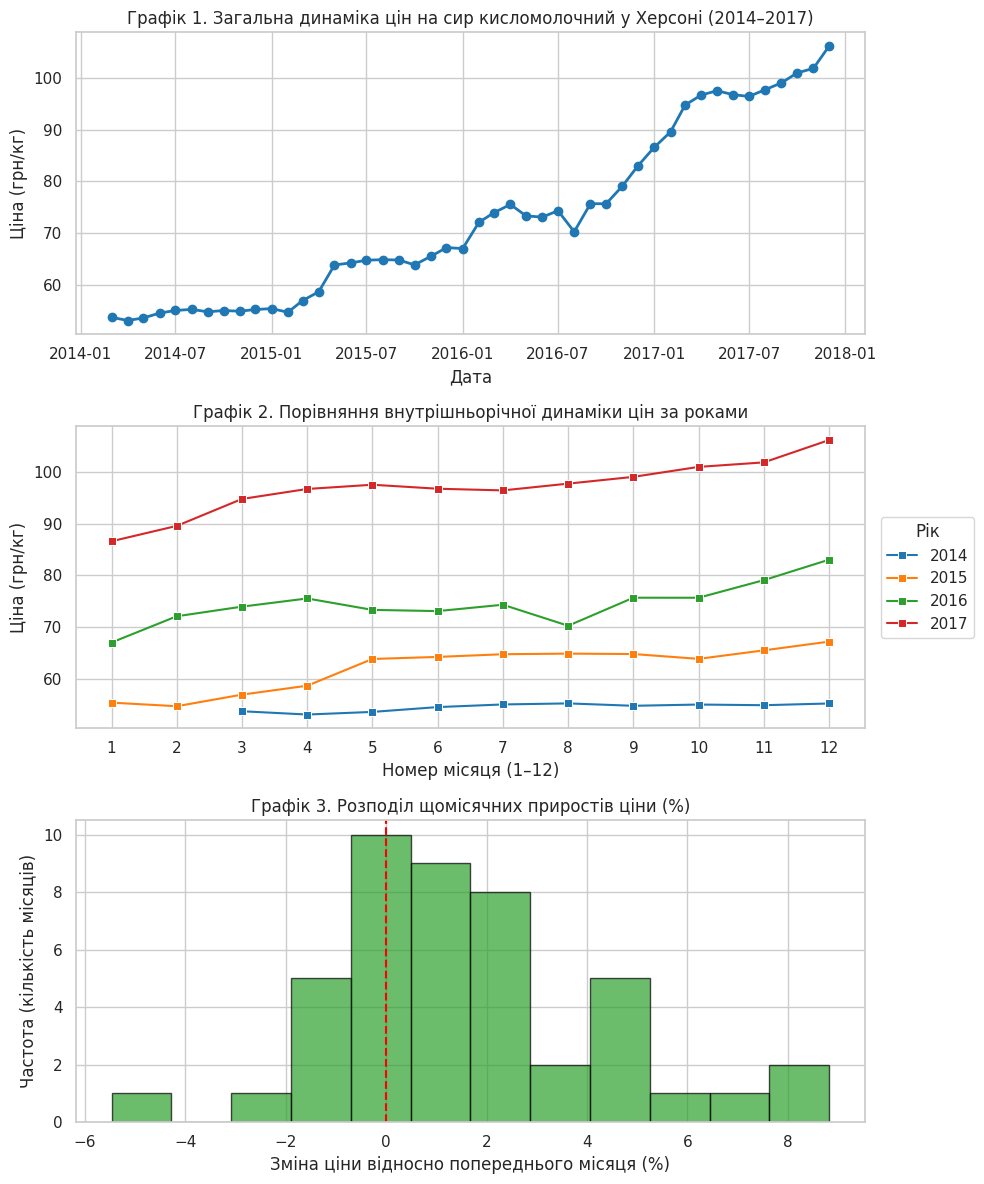

In [ ]:
# Завдання 3. Візуальна розвідка

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

axes[0].plot(ts_clean.index, ts_clean['ціна'], marker='o', color='#1f77b4', linewidth=2)
axes[0].set_title("Графік 1. Загальна динаміка цін на сир кисломолочний у Херсоні (2014–2017)")
axes[0].set_xlabel("Дата")
axes[0].set_ylabel("Ціна (грн/кг)")

ts_monthly = ts_clean.copy()
ts_monthly['Рік'] = ts_monthly.index.year
ts_monthly['Місяць'] = ts_monthly.index.month

sns.lineplot(data=ts_monthly, x='Місяць', y='ціна', hue='Рік', palette='tab10', marker='s', ax=axes[1])
axes[1].set_title("Графік 2. Порівняння внутрішньорічної динаміки цін за роками")
axes[1].set_xlabel("Номер місяця (1–12)")
axes[1].set_ylabel("Ціна (грн/кг)")
axes[1].set_xticks(range(1, 13))
axes[1].legend(title='Рік', loc='center left', bbox_to_anchor=(1.01, 0.5))

returns = ts_clean['ціна'].pct_change().dropna() * 100
axes[2].hist(returns, bins=12, color='#2ca02c', edgecolor='black', alpha=0.7)
axes[2].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[2].set_title("Графік 3. Розподіл щомісячних приростів ціни (%)")
axes[2].set_xlabel("Зміна ціни відносно попереднього місяця (%)")
axes[2].set_ylabel("Частота (кількість місяців)")

plt.tight_layout()
plt.show()

**Висновок до завдання 3:**

Графік 1 (лінійний, динаміка цін). Питання: як змінювалась ціна з часом і який загальний напрямок руху? Обрано лінію з маркерами, бо дані впорядковані в часі, а лінія показує порядок і неперервність ряду. Маркери дають побачити окремі місячні виміри. Шкала по осі Y лінійна в гривнях за кг: так видно реальні абсолютні зміни, а вісь не починається з нуля, бо цікавить саме рух ціни, а не її відношення до нуля.

Графік 2 (лінії по роках за номером місяця). Питання: чи повторюється річна форма ряду, тобто чи є сезонність? Обрано накладання ліній різних років на спільну вісь 1–12, бо так одразу порівнюється поведінка одного й того ж місяця в різні роки. Шкала лінійна, спільна для всіх років. Для 2014 року лінія починається з березня, бо ряд починається з 03.2014.

Графік 3 (гістограма місячних приростів у %). Питання: які типові зміни ціни за місяць і наскільки вони різкі та несиметричні? Обрано гістограму, бо питання про розподіл значень, а не про час. Відсоткові прирости, а не гривні, бо ціна зросла майже вдвічі і абсолютні зміни в 2014 і 2017 роках були б непорівнянними. Червона пунктирна лінія в нулі відділяє зростання від падіння.

Неочікувана знахідка: Для молочно-кислої продукції логічно було б очікувати щорічне літнє падіння цін (через збільшення надоїв сировини влітку). Проте графік 2 показує, що загальний інфляційний тренд пригнічує сезонність: форми графіків не повторюють одна одну, влітку ціни майже не змінюються, єдиний виражений спад спостерігався у серпні 2016 року, після чого ціна знову різко пішла вгору

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

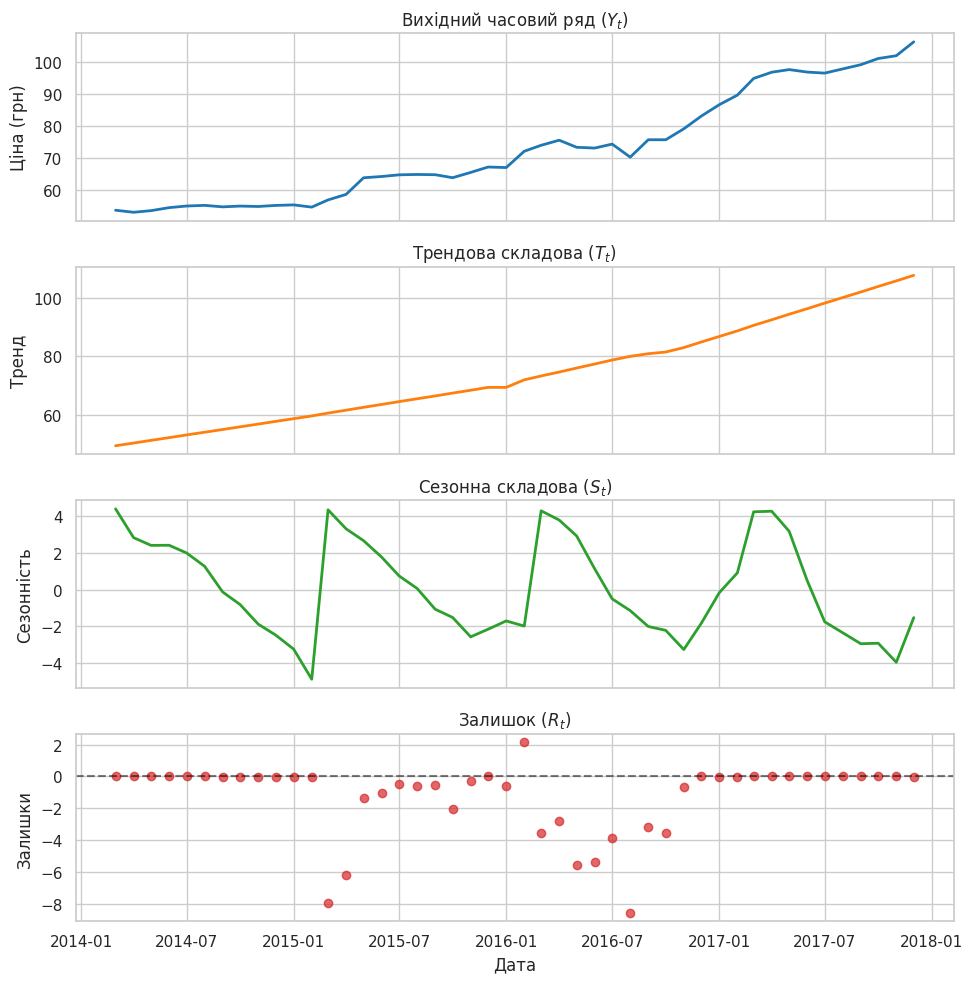

Сила тренду (F_T):      0.9823
Сила сезонності (F_S):  0.3946


In [ ]:
# Завдання 4. Розкладання на складові

import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

stl = STL(ts_clean['ціна'], period=12, robust=True)
res = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)

axes[0].plot(ts_clean.index, ts_clean['ціна'], color='#1f77b4', linewidth=2)
axes[0].set_title('Вихідний часовий ряд ($Y_t$)')
axes[0].set_ylabel('Ціна (грн)')

axes[1].plot(ts_clean.index, res.trend, color='#ff7f0e', linewidth=2)
axes[1].set_title('Трендова складова ($T_t$)')
axes[1].set_ylabel('Тренд')

axes[2].plot(ts_clean.index, res.seasonal, color='#2ca02c', linewidth=2)
axes[2].set_title('Сезонна складова ($S_t$)')
axes[2].set_ylabel('Сезонність')

axes[3].plot(ts_clean.index, res.resid, color='#d62728', marker='o', linestyle='none', alpha=0.7)
axes[3].axhline(0, color='black', linestyle='--', alpha=0.5)
axes[3].set_title('Залишок ($R_t$)')
axes[3].set_ylabel('Залишки')
axes[3].set_xlabel('Дата')

plt.tight_layout()
plt.show()

var_R = np.var(res.resid)
var_TR = np.var(res.trend + res.resid)
var_SR = np.var(res.seasonal + res.resid)

F_T = max(0, 1 - var_R / var_TR)
F_S = max(0, 1 - var_R / var_SR)

print(f"Сила тренду (F_T):      {F_T:.4f}")
print(f"Сила сезонності (F_S):  {F_S:.4f}")

**Висновок до завдання 4:**

У ряді виражена сезонність відсутня. Отримане значення F_S = 0.3946 є нижчим за пороговий рівень (0.64). Хоча математична декомпозиція виділяє невеликі внутрішньорічні коливання амплітудою +-4 грн, динаміка ціни майже повністю (F_T = 0.9823) визначається монотонним зростаючим трендом.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

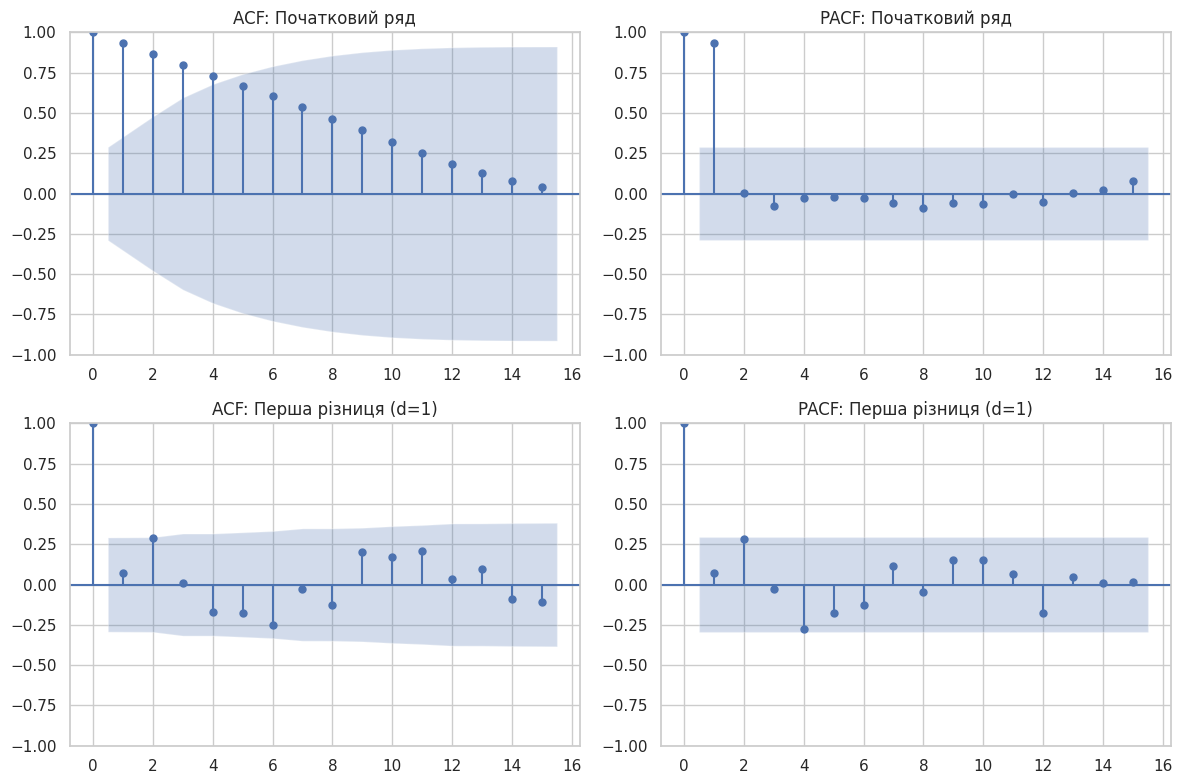

                 Ряд  ADF p-value  KPSS p-value
Початковий ряд (d=0)     0.997193          0.01
 Перша різниця (d=1)     0.009393          0.10


In [ ]:
# Завдання 5. Стаціонарність

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
warnings.filterwarnings('ignore')

ts_diff = ts_clean['ціна'].diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

plot_acf(ts_clean['ціна'], ax=axes[0, 0], title='ACF: Початковий ряд', lags=15)
plot_pacf(ts_clean['ціна'], ax=axes[0, 1], title='PACF: Початковий ряд', lags=15)

plot_acf(ts_diff, ax=axes[1, 0], title='ACF: Перша різниця (d=1)', lags=15)
plot_pacf(ts_diff, ax=axes[1, 1], title='PACF: Перша різниця (d=1)', lags=15)

plt.tight_layout()
plt.show()

def get_adf_pvalue(series):
    res = adfuller(series.dropna())
    return res[1]

def get_kpss_pvalue(series):
    res = kpss(series.dropna(), regression='c', nlags='auto')
    return res[1]

df_tests = pd.DataFrame({
    'Ряд': ['Початковий ряд (d=0)', 'Перша різниця (d=1)'],
    'ADF p-value': [get_adf_pvalue(ts_clean['ціна']), get_adf_pvalue(ts_diff)],
    'KPSS p-value': [get_kpss_pvalue(ts_clean['ціна']), get_kpss_pvalue(ts_diff)]
})

print("=" * 55)
print(df_tests.to_string(index=False))
print("=" * 55)

**Висновок до завдання 5:**

Для початкового ряду графік ACF демонструє повільне лінійне згасання, що є  ознакою нестаціонарності та наявності тренду. Після першого диференціювання автокореляції майже зникають (більшість лагів в межах довірчої зони), що свідчить про стаціонарність приростів.

Результати тестів:
- Початковий ряд (d=0): ADF p-value = 0.997 (>0.05), KPSS p-value = 0.01 (<0.05). Обидва тести узгоджуються і вказують на нестаціонарність початкового ряду.
- Перша різниця (d=1): ADF p-value = 0.0094 (<0.05), KPSS p-value = 0.10 (>0.05). Обидва тести узгоджуються між собою і підтверджують стаціонарність першої різниці.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [ ]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка

import numpy as np
import pandas as pd

series = ts_clean['ціна'].copy()
n_folds = 7
horizon = 3

def evaluate_baselines_rolling(series, n_folds=7, horizon=3):
    names = ['Naive', 'SNaive', 'Mean', 'Drift']
    all_actual = []
    all_pred = {name: [] for name in names}

    start_train_len = len(series) - n_folds * horizon

    for i in range(n_folds):
        train_end = start_train_len + i * horizon
        train = series.iloc[:train_end]
        test = series.iloc[train_end:train_end + horizon]

        pred_naive = np.full(horizon, train.iloc[-1])
        pred_snaive = series.iloc[train_end - 12 : train_end - 12 + horizon].values
        pred_mean = np.full(horizon, train.mean())
        slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
        pred_drift = train.iloc[-1] + slope * np.arange(1, horizon + 1)

        preds = {'Naive': pred_naive, 'SNaive': pred_snaive,
                 'Mean': pred_mean, 'Drift': pred_drift}

        all_actual.extend(test.values)
        for name in names:
            all_pred[name].extend(preds[name])

    actual = np.array(all_actual)
    res = {}
    for name in names:
        err = actual - np.array(all_pred[name])
        res[name] = {
            'MAE': np.mean(np.abs(err)),
            'RMSE': np.sqrt(np.mean(err ** 2)),
            'MAPE (%)': np.mean(np.abs(err / actual)) * 100
        }
    return pd.DataFrame(res).T, len(actual)

df_rolling, n_points = evaluate_baselines_rolling(series, n_folds=7, horizon=3)

np.random.seed(42)
train_size = int(len(series) * 0.75)
test_idx = np.random.choice(series.index, size=len(series) - train_size, replace=False)
train_rand = series.drop(test_idx)
test_rand = series.loc[test_idx]

errs_rand = []
for t_date in test_rand.index:
    past_train = train_rand[train_rand.index < t_date]
    if len(past_train) > 0:
        pred_val = past_train.iloc[-1]
        errs_rand.append(abs(test_rand.loc[t_date] - pred_val))

mae_rand_naive = np.mean(errs_rand)
mae_roll_naive = df_rolling.loc['Naive', 'MAE']

print("=" * 60)
print(f"Рухомий початок (7х3), метрики по всіх {n_points} прогнозах разом")
print("=" * 60)
print(df_rolling.round(3))
print("\n" + "=" * 60)
print(f"MAE Naive, випадковий поділ 75/25: {mae_rand_naive:.3f} грн")
print(f"MAE Naive, рухомий початок:        {mae_roll_naive:.3f} грн")
print(f"Відношення (рухомий / випадковий): {mae_roll_naive / mae_rand_naive:.2f} раза")
print("=" * 60)


Рухомий початок (7х3), метрики по всіх 21 прогнозах разом
           MAE    RMSE  MAPE (%)
Naive    3.070   4.158     3.434
SNaive  17.796  18.873    19.692
Mean    22.941  24.384    25.307
Drift    2.275   3.110     2.639

MAE Naive, випадковий поділ 75/25: 1.474 грн
MAE Naive, рухомий початок:        3.070 грн
Відношення (рухомий / випадковий): 2.08 раза


**Висновок до завдання 6:**

Ретроспективна перевірка з рухомим початком (7 фолдів по 3 кроки) показала, що найкращим базисом є дрейф. Він виграє, бо ряд має сильний майже монотонний тренд (F_T = 0.98), і продовження середнього приросту краще відображає зростання, ніж просте повторення останнього значення (наївний). Сезонний наївний і середнє значно гірші: перший через відсутність сезонності (F_S = 0.39), другий тому, що середнє за минуле не враховує зростання ціни.

Для порівняння, оцінка наївного базису випадковим поділом 75/25 дала MAE у ~2.1 раза менше. Це занижена оцінка похибки: у випадковому поділі тестові точки оточені навчальними, що призводить до витоку інформації з майбутнього.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

 Порівняння ARIMA(1,1,1) та кращого базису (DRIFT) на 7 фолдах
                 MAE   RMSE  MAPE (%)
ARIMA(1,1,1)   2.941  3.829     3.398
Drift (Базис)  2.275  3.110     2.639


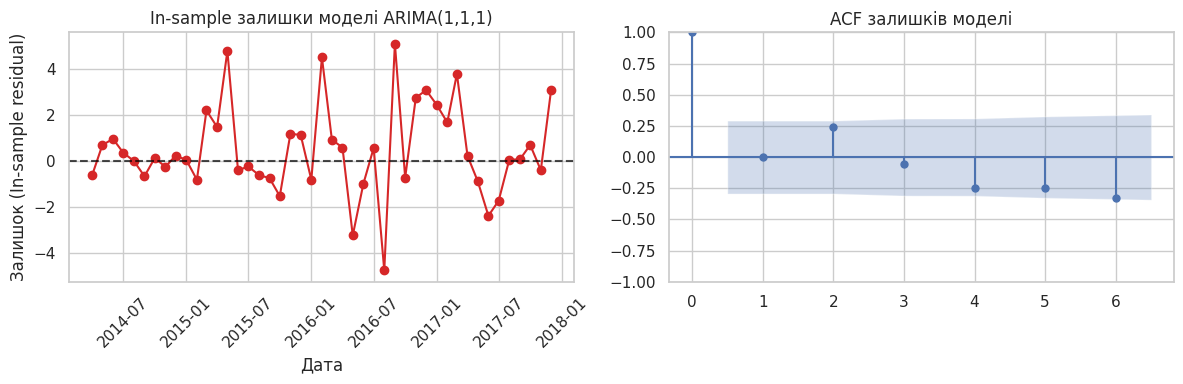

In [ ]:
# Завдання 7. Модель ARIMA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf

series = ts_clean['ціна'].copy()
n_folds = 7
horizon = 3
start_train_len = len(series) - n_folds * horizon

all_actual = []
all_pred_arima = []

for i in range(n_folds):
    train_end = start_train_len + i * horizon
    train = series.iloc[:train_end]
    test = series.iloc[train_end:train_end + horizon]

    model = ARIMA(train, order=(1, 1, 1))
    model_fit = model.fit()

    pred = model_fit.forecast(steps=horizon)

    all_actual.extend(test.values)
    all_pred_arima.extend(pred.values)

actual = np.array(all_actual)
pred_arima = np.array(all_pred_arima)

err_arima = actual - pred_arima
mae_arima = np.mean(np.abs(err_arima))
rmse_arima = np.sqrt(np.mean(err_arima ** 2))
mape_arima = np.mean(np.abs(err_arima / actual)) * 100

df_compare = pd.DataFrame({
    'MAE': [mae_arima, df_rolling.loc['Drift', 'MAE']],
    'RMSE': [rmse_arima, df_rolling.loc['Drift', 'RMSE']],
    'MAPE (%)': [mape_arima, df_rolling.loc['Drift', 'MAPE (%)']]
}, index=['ARIMA(1,1,1)', 'Drift (Базис)'])

print("=" * 70)
print(" Порівняння ARIMA(1,1,1) та кращого базису (DRIFT) на 7 фолдах")
print("=" * 70)
print(df_compare.round(3))
print("=" * 70)

full_model = ARIMA(series, order=(1, 1, 1)).fit()
model_residuals = full_model.resid.iloc[1:]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(model_residuals, marker='o', color='#d62728', linestyle='-')
axes[0].axhline(0, color='black', linestyle='--', alpha=0.7)
axes[0].set_title('In-sample залишки моделі ARIMA(1,1,1)')
axes[0].set_xlabel('Дата')
axes[0].set_ylabel('Залишок (In-sample residual)')

plot_acf(model_residuals, ax=axes[1], lags=6, title='ACF залишків моделі')

axes[0].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Висновок до завдання 7:**

ARIMA(1,1,1) на 7 фолдах по 3 кроки дала MAE = 2.94, RMSE = 3.83, MAPE = 3.4%. Це гірше за найкращий базис, дрейф (MAE = 2.28, RMSE = 3.11, MAPE = 2.64%), хоча трохи краще за наївний (MAE = 3.07). Отже, ця модель не виправдовує своєї складності. Ймовірна причина: ряд має сильний тренд, а модель без константи не продовжує середній приріст, тоді як дрейф це робить; крім того, на короткому ряді два параметри оцінюються ненадійно.

 За виглядом ACF і PACF першої різниці (лаги 1–15 майже всі незначущі, лише лаги 2 і 4 на межі) я б обрала найпростіший порядок ARIMA(0,1,0); лаги 2 і 4 можуть бути випадковими.

Залишки ARIMA(1,1,1) коливаються приблизно від −5 до +5 грн. Найбільші відхилення припадають на періоди стрибків ціни, які модель не передбачила. ACF залишків на лагах 4-6 має від'ємні значення, причому лаг 6 виходить за межі довірчої зони. Явної автокореляції немає, але слабкий натяк на структуру лишається; на ряді з 45 точок це не можна надійно ні підтвердити, ні спростувати.


## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

 Результати сумарного сканування точки зміни режиму
1. Знайдена дата зміни режиму: 2017-03-01
2. Значення t-статистики:     -16.4656
3. p-value:        4.2823e-20
4. Середнє рівнів до дати:     65.54 грн
5. Середнє рівнів після дати:  98.83 грн


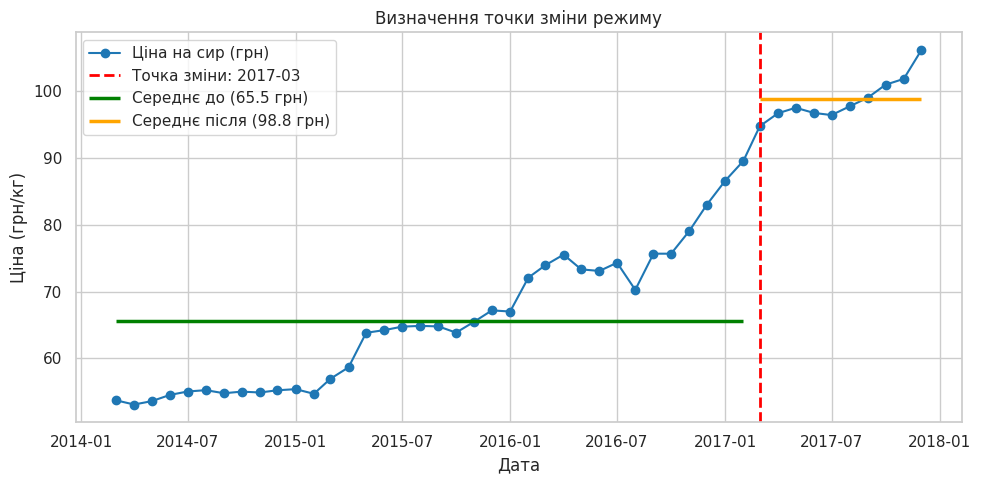

In [ ]:
# Завдання 8. Точка зміни режиму

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

y = ts_clean['ціна']
results = []

for i in range(6, len(y) - 6):
    before, after = y.iloc[:i], y.iloc[i:]
    t, p = stats.ttest_ind(before, after, equal_var=False)
    results.append((y.index[i], t, p, before.mean(), after.mean()))

res = pd.DataFrame(results, columns=['дата', 't', 'p_val', 'до', 'після'])

best = res.loc[res['t'].abs().idxmax()]

print("=" * 60)
print(" Результати сумарного сканування точки зміни режиму")
print("=" * 60)
print(f"1. Знайдена дата зміни режиму: {best['дата'].strftime('%Y-%m-%d')}")
print(f"2. Значення t-статистики:     {best['t']:.4f}")
print(f"3. p-value:        {best['p_val']:.4e}")
print(f"4. Середнє рівнів до дати:     {best['до']:.2f} грн")
print(f"5. Середнє рівнів після дати:  {best['після']:.2f} грн")
print("=" * 60)

plt.figure(figsize=(10, 5))
plt.plot(y.index, y, marker='o', label='Ціна на сир (грн)', color='#1f77b4')

split_date = best['дата']
plt.axvline(split_date, color='red', linestyle='--', linewidth=2, label=f"Точка зміни: {split_date.strftime('%Y-%m')}")

before_mask = y.index < split_date
after_mask = y.index >= split_date

plt.hlines(best['до'], y.index[before_mask][0], y.index[before_mask][-1],
          colors='green', linestyles='-', linewidth=2.5, label=f"Середнє до ({best['до']:.1f} грн)")
plt.hlines(best['після'], y.index[after_mask][0], y.index[after_mask][-1],
          colors='orange', linestyles='-', linewidth=2.5, label=f"Середнє після ({best['після']:.1f} грн)")

plt.title("Визначення точки зміни режиму")
plt.xlabel("Дата")
plt.ylabel("Ціна (грн/кг)")
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Висновок до завдання 8:**

Сканування за t-статистикою (кандидатні дати з відступом 6 точок від країв) вказало на березень 2017: t = −16.5, середній рівень до 65.5 грн, після 98.8 грн. Формальне p-значення не можна вважати надійним: перебір багатьох дат завищує значущість, а місячні ціни сильно автокорельовані, тоді як t-тест припускає незалежність. До того ж ряд має сильний тренд (F_T = 0.98), тому метод частково сприймає зростання за зсув рівня. Тож різниця рівнів реальна, але статистично довести, що це окрема точка зміни режиму, а не частина тренду, не можна. Від сезонного сплеску ця точка відрізняється тим, що ціна після неї не повертається на колишній рівень і подібних підйомів у ті самі місяці інших років немає (сезонність слабка, F_S = 0.39).

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

**Висновок до завдання 9:**

#### 1. Перелік знайдених методологічних помилок

1. **Помилка №1 (Завантаження даних та перевірка пропусків):**
   * **Суть:** Відсутнє вирівнювання за повною часовою сіткою (`grid`), перевірка `isna().sum()` виконана на некоректно сформованій таблиці (45 точок замість 46).
   * **Небезпека:** Автор робить висновок про «відсутність пропусків». Пропущений місяць зрушив часову вісь, порушивши постійність кроку, що викривляє автокореляції та диференціювання.

2. **Помилка №2 (Динаміка цін):**
   * **Суть:** Глобальний економічний висновок про «зниження купівельної спроможності» зроблено на основі порівняння двох крайніх точок одного товару.
   * **Небезпека:** Ігнорується внутрішня динаміка та специфіка аграрного ринку. Робити макроекономічні висновки без даних про інфляцію чи доходи населення некоректно.

3. **Помилка №3 (Порівняння з іншим товаром):**
   * **Суть:** Порівняння похибки MAE (у грн) для двох товарів із різним ціновим масштабом (гречка vs яловичина).
   * **Небезпека:** Масштабозалежна метрика MAE дає хибний висновок про те, що яловичина прогнозується «гірше», хоча у відносних відсотках (MAPE) її точність вища.

4. **Помилка №4 (Кореляція цін у двох областях):**
   * **Суть:** Твердження про причинно-наслідковий зв'язок на основі парної кореляції нестаціонарних рядів (r = 0.996).
   * **Небезпека:** Прояв «хибної кореляції» через спільний тренд. Спільна динаміка цін не означає, що один регіон визначає ціни в іншому.

5. **Помилка №5 (STL-декомпозиція):**
   * **Суть:** Висновок про наявність сезонності зроблено суто за наявністю математичного вектора STL та його амплітудою в гривнях.
   * **Небезпека:** STL завжди виділяє сезонний компонент. Ігнорування розрахунку сили сезонності (F_S) призводить до безпідставного застосування сезонних моделей.

6. **Помилка №6 (Перевірка стаціонарності):**
   * **Суть:** Перекручено суть ADF-тесту: при p-value = 0.233 > 0.05 зроблено висновок «ряд стаціонарний». Одразу взято другу різницю без перевірки першої.
   * **Небезпека:** Невірна інтерпретація загрожує роботою з нестаціонарним рядом, а необґрунтоване d=2 призводить до передиференціювання та внесення шуму.

7. **Помилка №7 (Пошук аномалій):**
   * **Суть:** Пошук аномалій через Z-score для рівня нестаціонарного ряду із загальними mean/std (ще й поріг 1.3 в коді замість 2.0).
   * **Небезпека:** Цілий рік у минулому оголошено «аномальним» просто через те, що тоді ціна була нижчою за майбутнє середнє значення.

8. **Помилка №8 (Поділ вибірки та ARIMA):**
   * **Суть:** Використано випадкове перемішування для часового ряду.
   * **Небезпека:** Призводить до витоку даних з майбутнього, роблячи оцінку моделі викривлено оптимістичною та беззмістовною.

---
#### 2. Виправлення трьох найсерйозніших помилок

* **Виправлення Помилки №1 (Часова сітка та пропуски):**
  Виконати .reindex(grid) одразу після фільтрації, щоб пропущений місяць з'явився як NaN, після чого застосувати лінійну інтерполяцію.

* **Виправлення Помилки №6 (Перевірка стаціонарності):**
  Зафіксувати правило інтерпретації ADF-тесту: якщо p-value > 0.05, ряд є нестаціонарним. Слід послідовно перевірити стаціонарність першої різниці, і якщо для неї p-value < 0.05, зупинитися на першому порядку диференціювання.

* **Виправлення Помилки №8 (Поділ вибірки для часових рядів):**
  Використовувати послідовний поділ за часом (наприклад, перші 75% за часом train, останні 25% test) або застосувати ретроспективну крос-валідацію для часових рядів.




## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [ ]:
# Завдання 10. Експорт ряду для Orange
import pandas as pd

df_reset = ts_clean.reset_index()

date_col = 'date' if 'date' in df_reset.columns else df_reset.columns[0]
df_orange = df_reset[[date_col, 'ціна']].copy()

df_orange.columns = ['date', 'price']

df_orange['date'] = pd.to_datetime(df_orange['date']).dt.strftime('%Y-%m-%d')

filename = 'ряд_для_orange.csv'
df_orange.to_csv(filename, index=False, encoding='utf-8')

check_df = pd.read_csv(filename)

print(f"1. Стовпчики у файлі:                  {list(check_df.columns)}")
print(f"2. Кількість рядків даних (без заголовка): {len(check_df)}")
print(f"3. Кількість порожніх значень:      {check_df.isna().sum().sum()}")
print("\nПерші 3 рядки файлу:")
print(check_df.head(3))

if len(check_df) == 46 and check_df.isna().sum().sum() == 0 and list(check_df.columns) == ['date', 'price']:
    print("Файл повністю відповідає вимогам.")

1. Стовпчики у файлі:                  ['date', 'price']
2. Кількість рядків даних (без заголовка): 46
3. Кількість порожніх значень:      0

Перші 3 рядки файлу:
         date    price
0  2014-03-01  53.7200
1  2014-04-01  53.0867
2  2014-05-01  53.5933
Файл повністю відповідає вимогам.


---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

**Висновок до завдання 11:**

Побудований потік

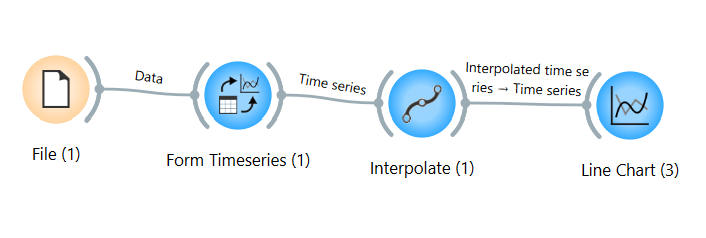

Line chart

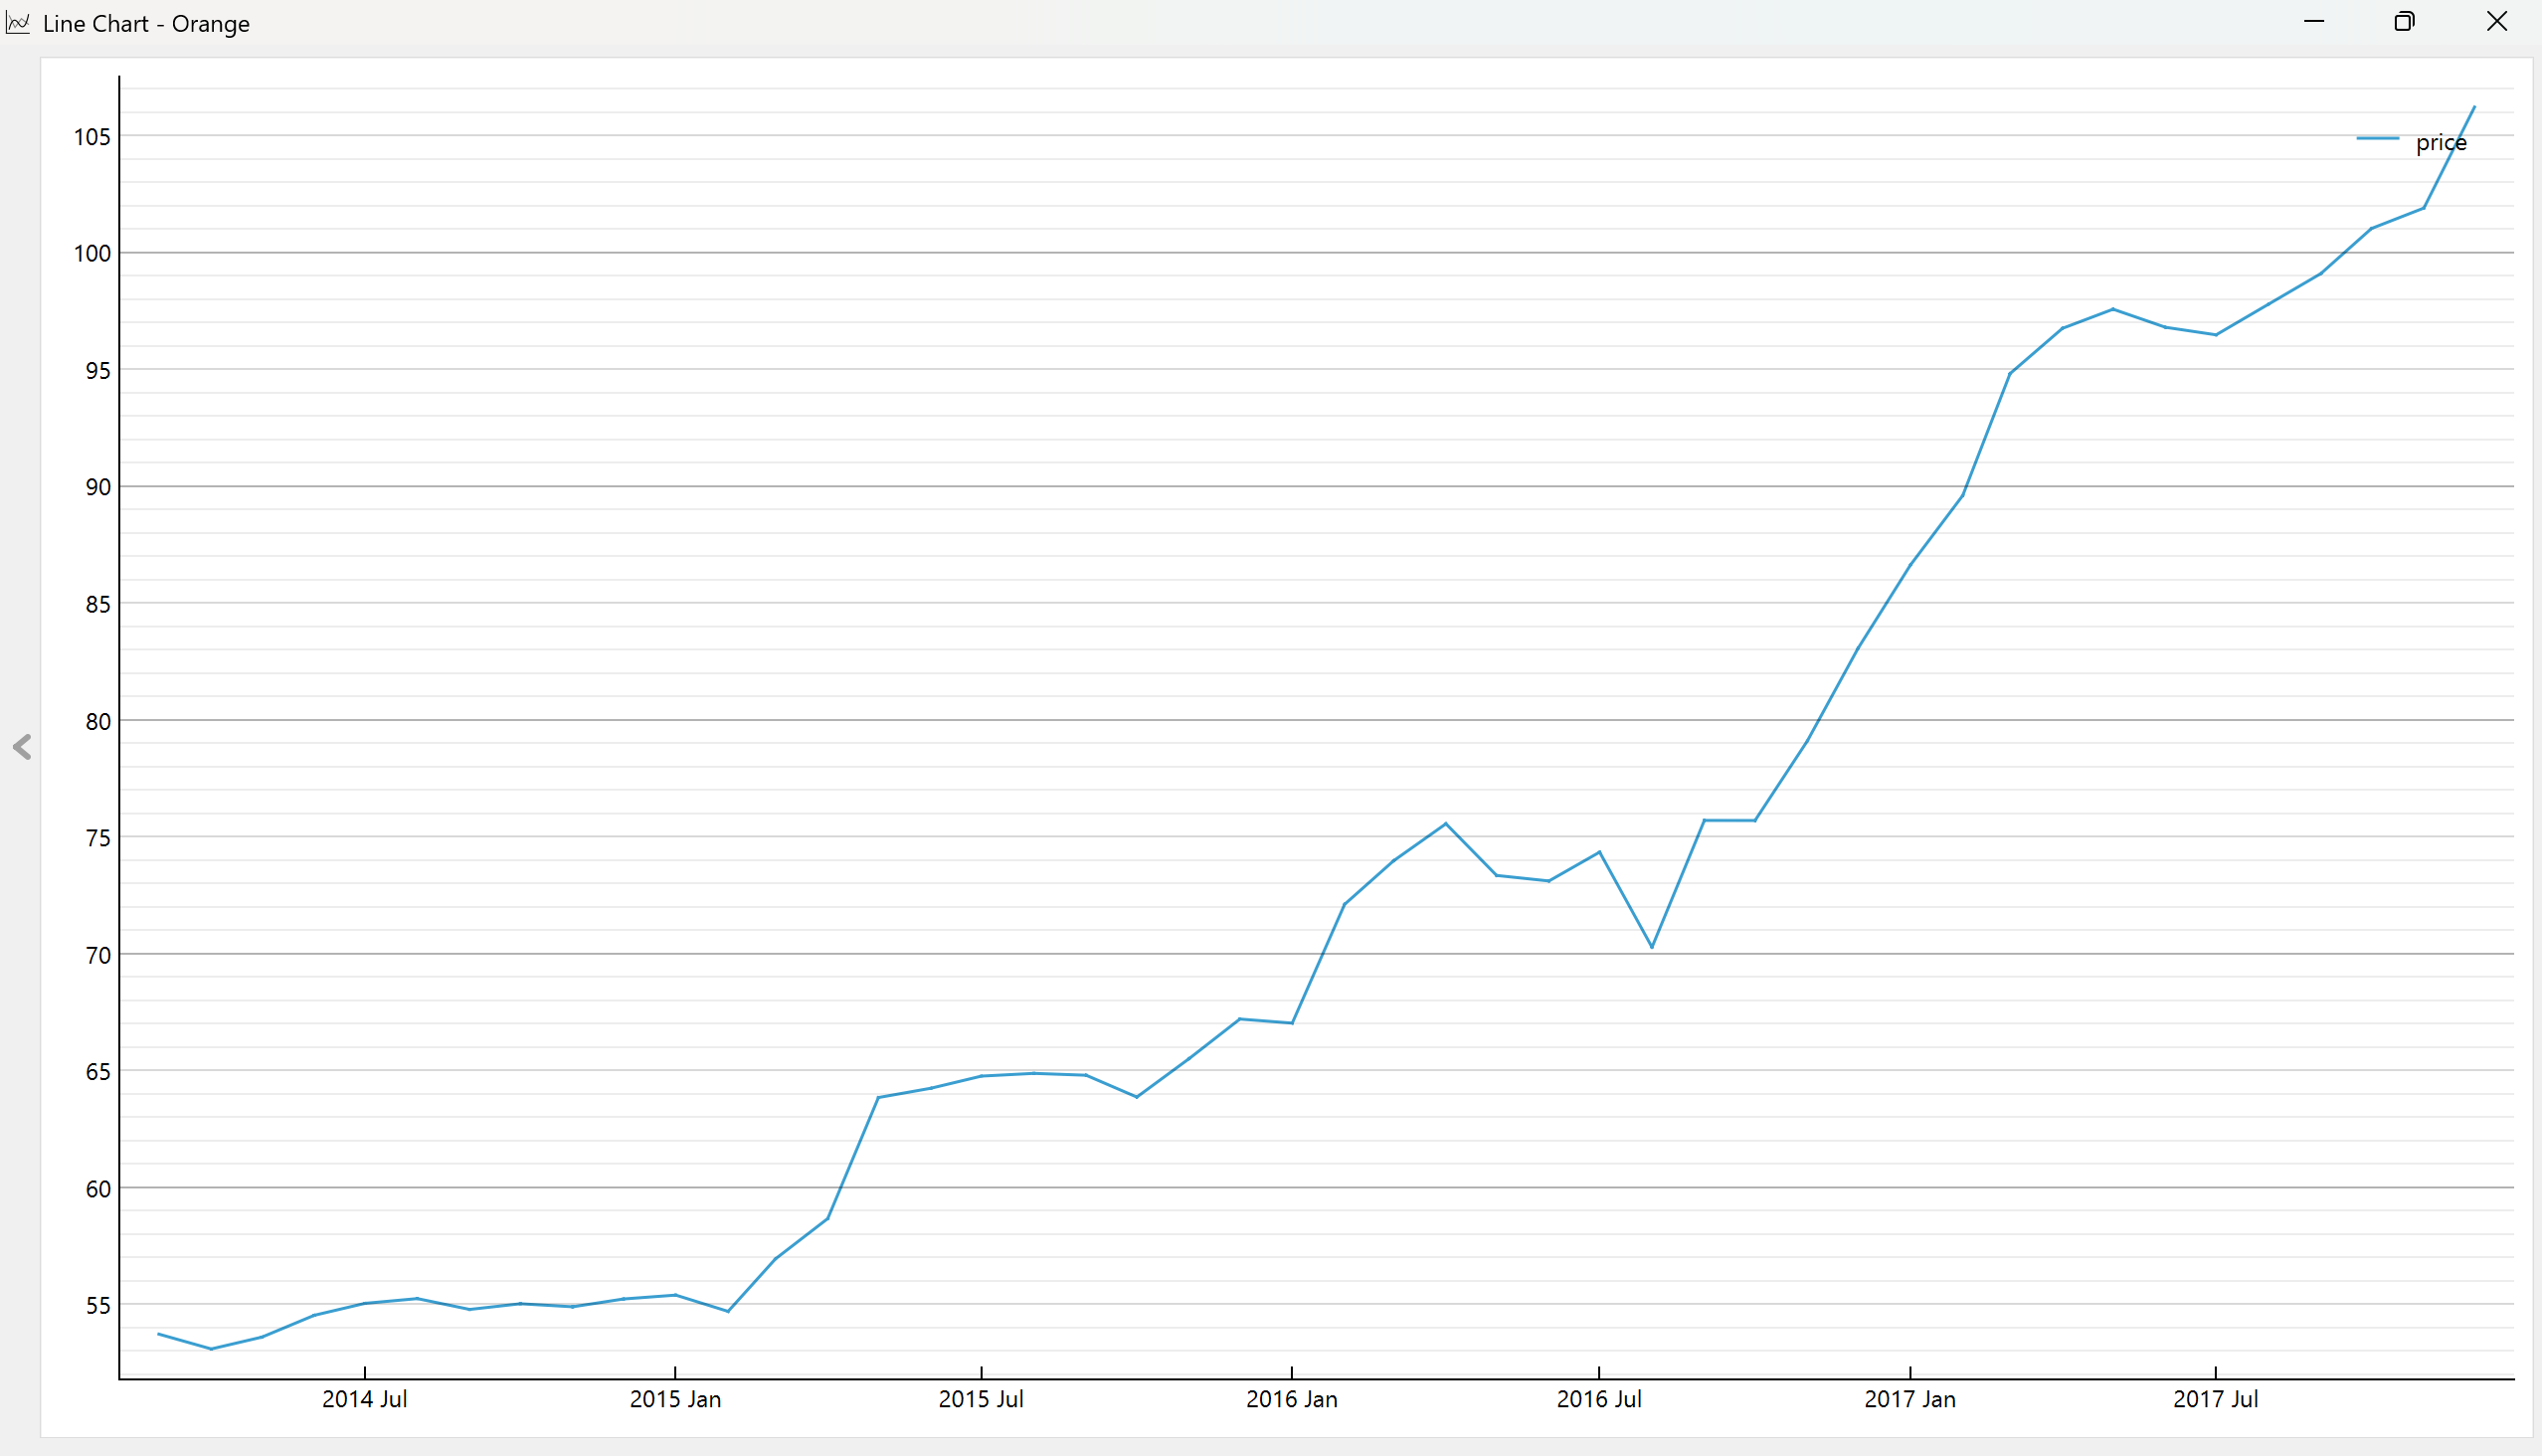

Графік з завдання 3

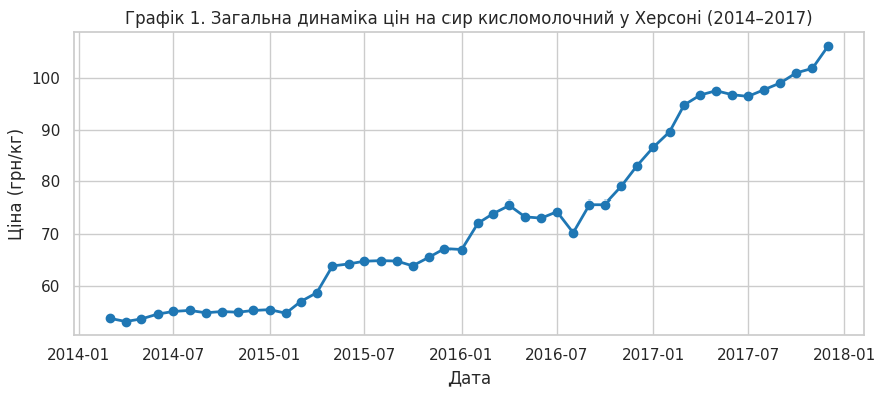

Потік File → As Timeseries → Interpolate → Line Chart побудовано. У віджеті File змінну date розпізнано як time, а price як numeric; у Data Table 46 спостережень без пропусків. Line Chart в Orange збігається з графіком 1 із завдання 3: однакова загальна форма, однаковий діапазон значень (приблизно від 53 до 106 грн) і однакові локальні особливості, зокрема просідання в серпні 2016.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

Корелограма Orange для вихідного ряду

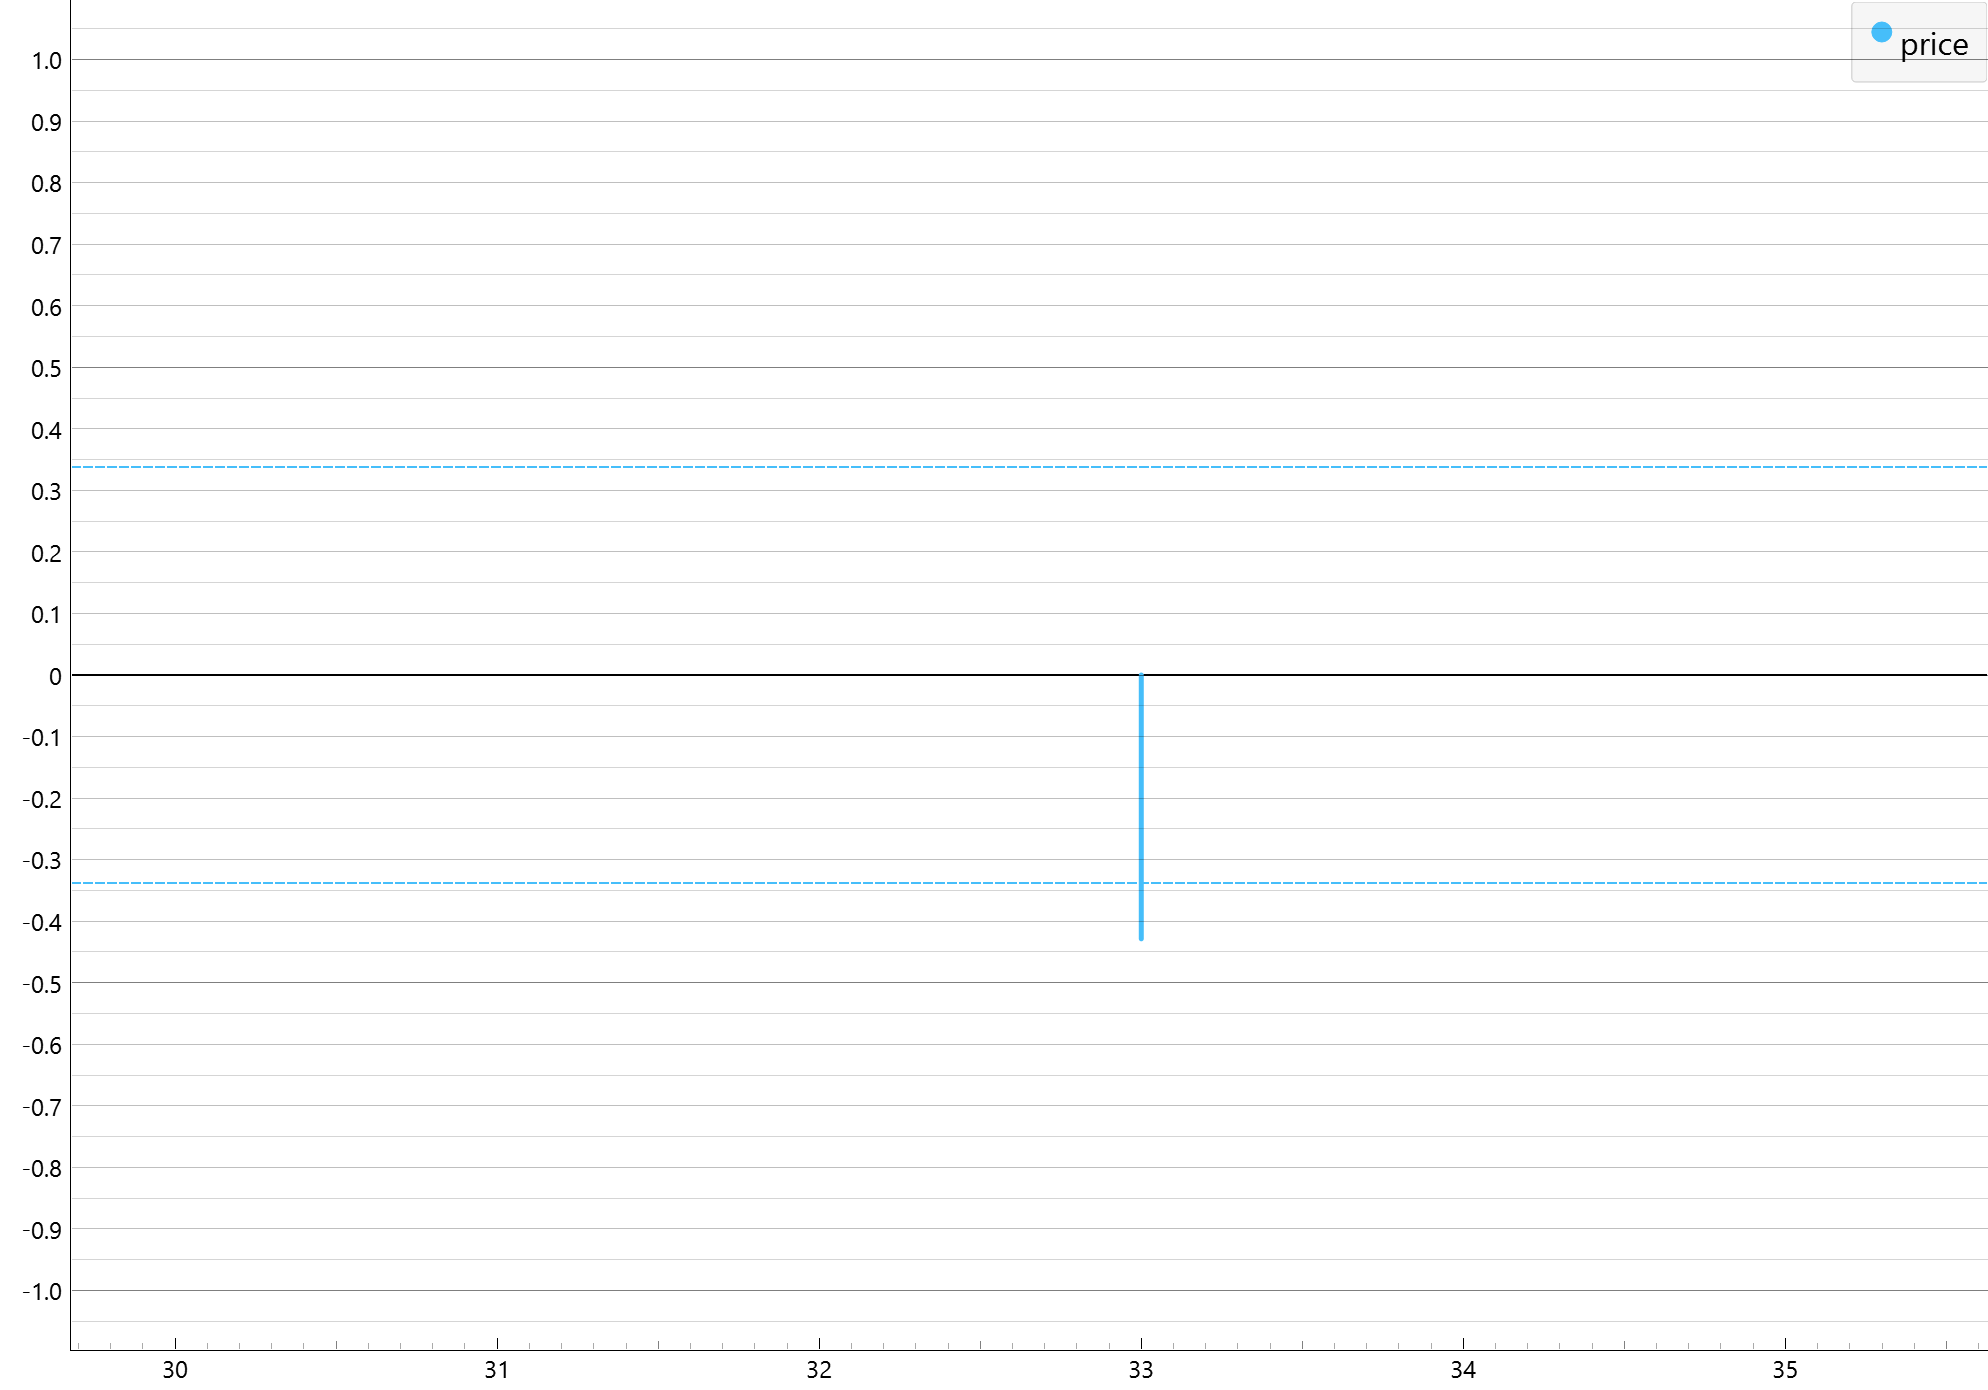

Корелограма для перших різниць

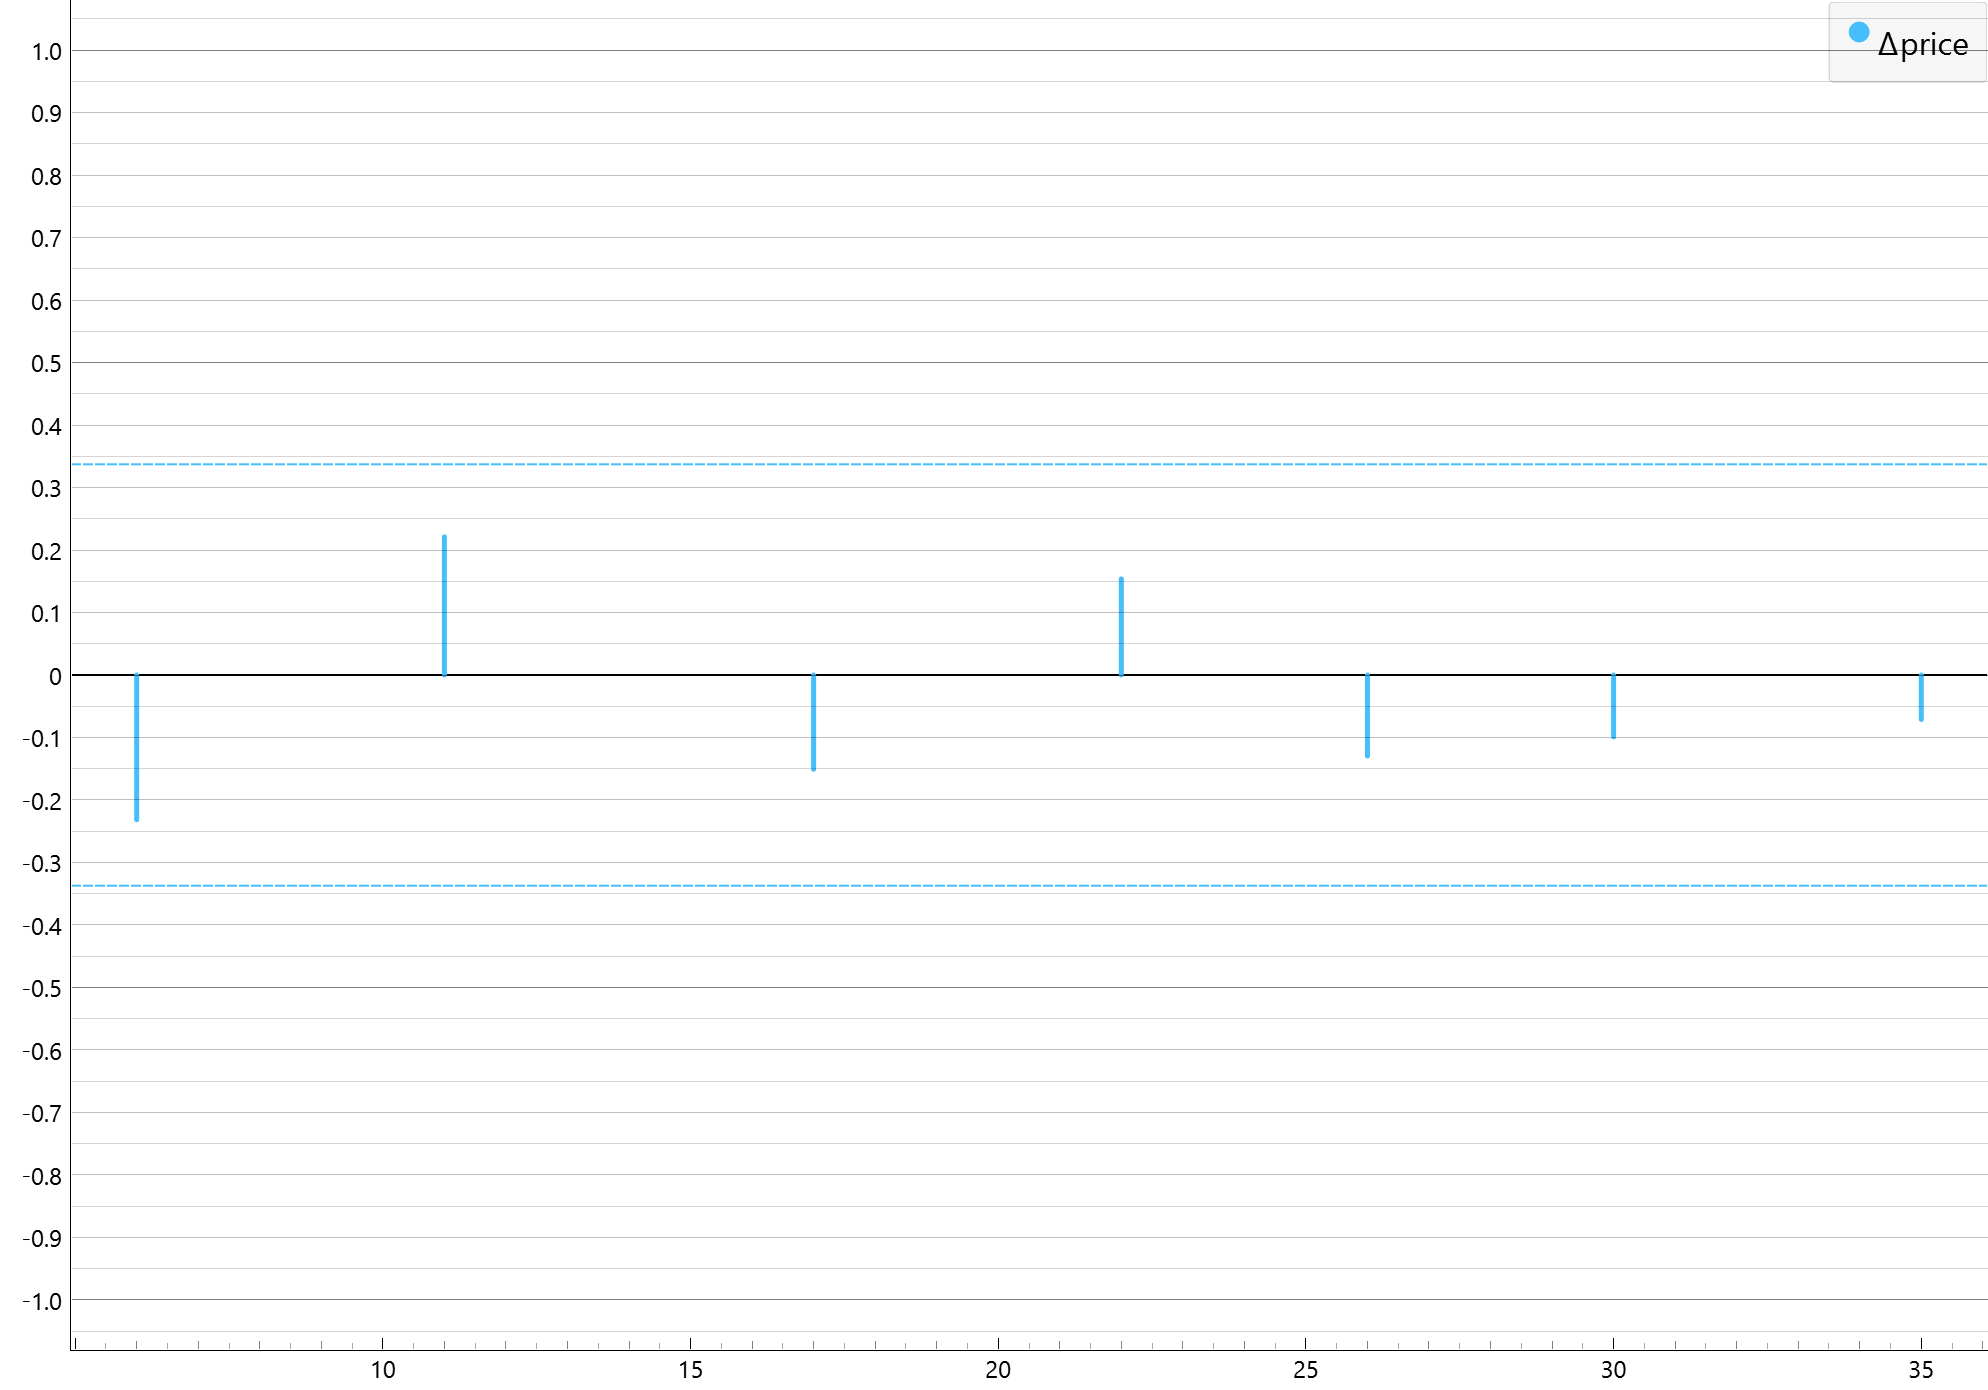

In [ ]:
# Завдання 12. Автокореляція та диференціювання
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf

y  = ts_clean['ціна']
dy = y.diff().dropna()

acf_y  = acf(y,  nlags=35, fft=False)
acf_dy = acf(dy, nlags=35, fft=False)

orange_dy = {6: -0.23, 11: 0.22, 17: -0.15, 22: 0.16, 26: -0.13, 30: -0.10, 35: -0.07}
orange_y  = {33: -0.43}

rows = []
for lag, o in orange_dy.items():
    rows.append(['Δprice', lag, o, round(acf_dy[lag], 3), round(abs(o - acf_dy[lag]), 3)])
for lag, o in orange_y.items():
    rows.append(['price', lag, o, round(acf_y[lag], 3), round(abs(o - acf_y[lag]), 3)])

cmp = pd.DataFrame(rows, columns=['ряд', 'лаг', 'Orange', 'Python', '|різниця|'])
print(cmp.to_string(index=False))


   ряд  лаг  Orange  Python  |різниця|
Δprice    6   -0.23  -0.253      0.023
Δprice   11    0.22   0.205      0.015
Δprice   17   -0.15  -0.163      0.013
Δprice   22    0.16   0.142      0.018
Δprice   26   -0.13  -0.165      0.035
Δprice   30   -0.10  -0.059      0.041
Δprice   35   -0.07  -0.053      0.017
 price   33   -0.43  -0.429      0.001


Віджет Correlogram в Orange відображає не всі лаги, а лише ті, де модуль автокореляції є локальним максимумом у вікні ±3 лаги. Решта лагів відфільтровується до побудови графіка. Тому для вихідного ряду, де ACF монотонно спадає і локальних максимумів майже немає, показано лише лаг 33, а для першої різниці лише лаги 6, 11, 17, 22, 26, 30, 35. Лаги 1–5 та інші проміжні не пройшли цей фільтр, бо поруч із ними є більші за модулем значення (зокрема лаг 0, що дорівнює 1). Отже, це відмінність у способі відображення, а не в обчисленні: statsmodels малює ACF на всіх лагах, а Orange лише відібрані піки.

Дані на вході однакові: у Data Table 46 спостережень без пропусків, date розпізнано як time, price як numeric, Line Chart збігається з графіком із Python. Для лагів, які Orange все-таки відобразив, значення збігаються з ACF із statsmodels із точністю близько 0.01–0.04 (таблиця вище; значення з Orange зчитувала з графіка на око, тому така похибка очікувана). Довірчий інтервал Orange (≈ ±0.34) теж рахується інакше, ніж у statsmodels: за формулою 1.96·√((1 + 2·Σacf²)/n), де сума береться по відображених лагах, а не по всіх.

Висновок щодо значущості лагів збігається в обох середовищах: у першій різниці жоден із показаних Orange лагів не виходить за межі довірчого інтервалу, що узгоджується із завданням 5 (значущої автокореляції в приростах немає). У statsmodels на межі значущості були лише лаги 2 і 4, і саме їх Orange не показав, бо вони не пройшли фільтр локальних максимумів, тому порівняти їх напряму неможливо.

###Сезонно скоригований ряд
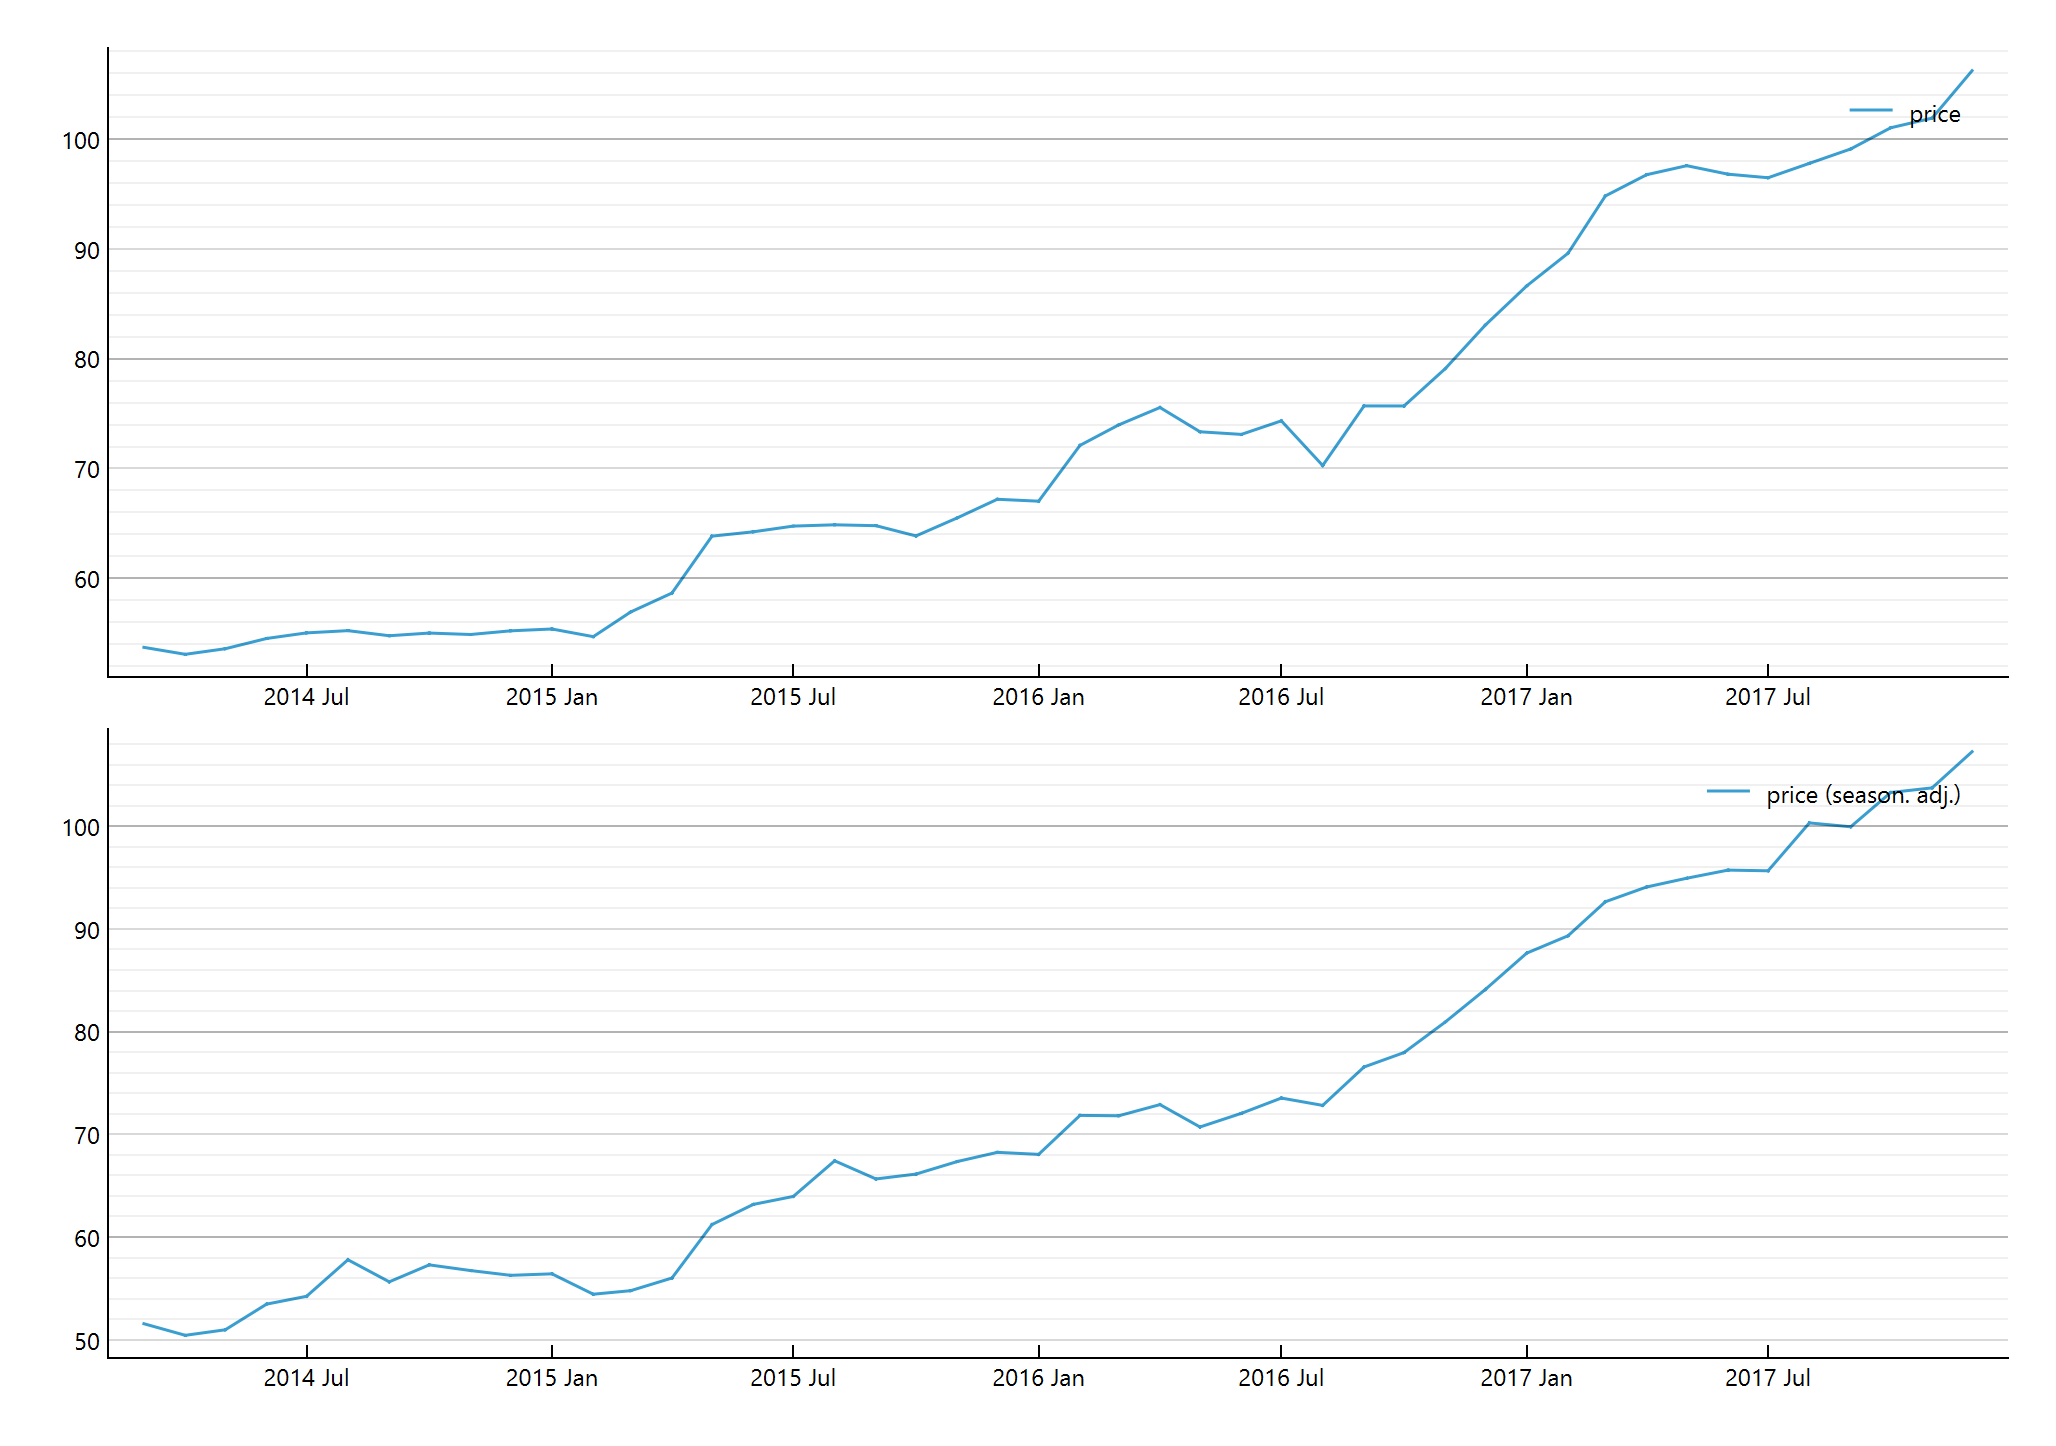

###Сезонність, тренд, залишки
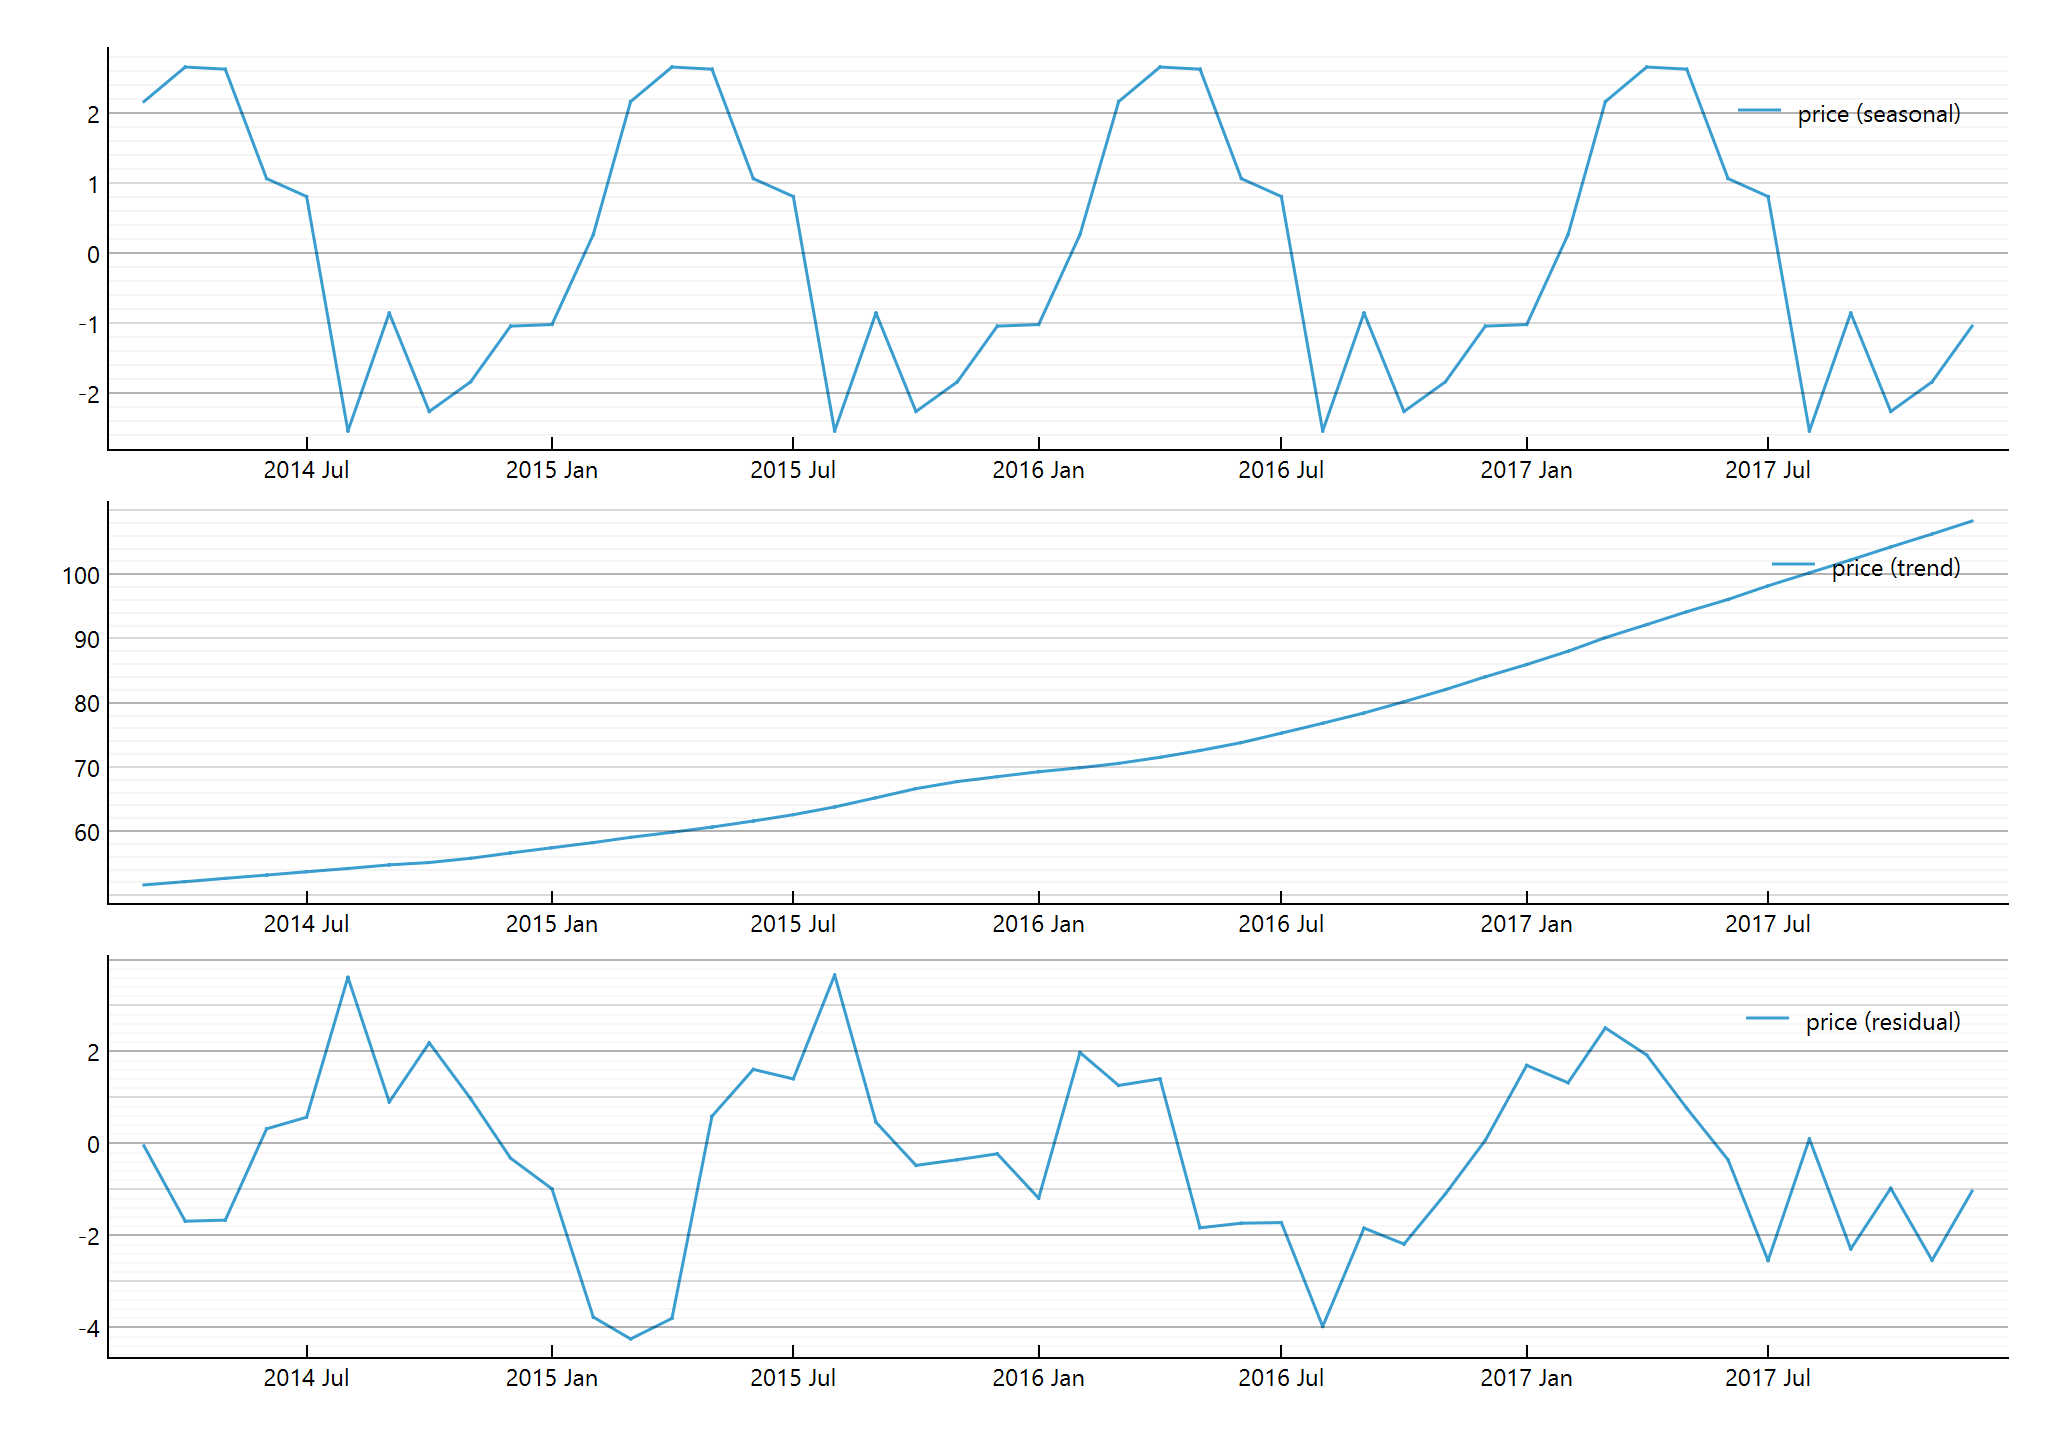

### STL з 4 завдання
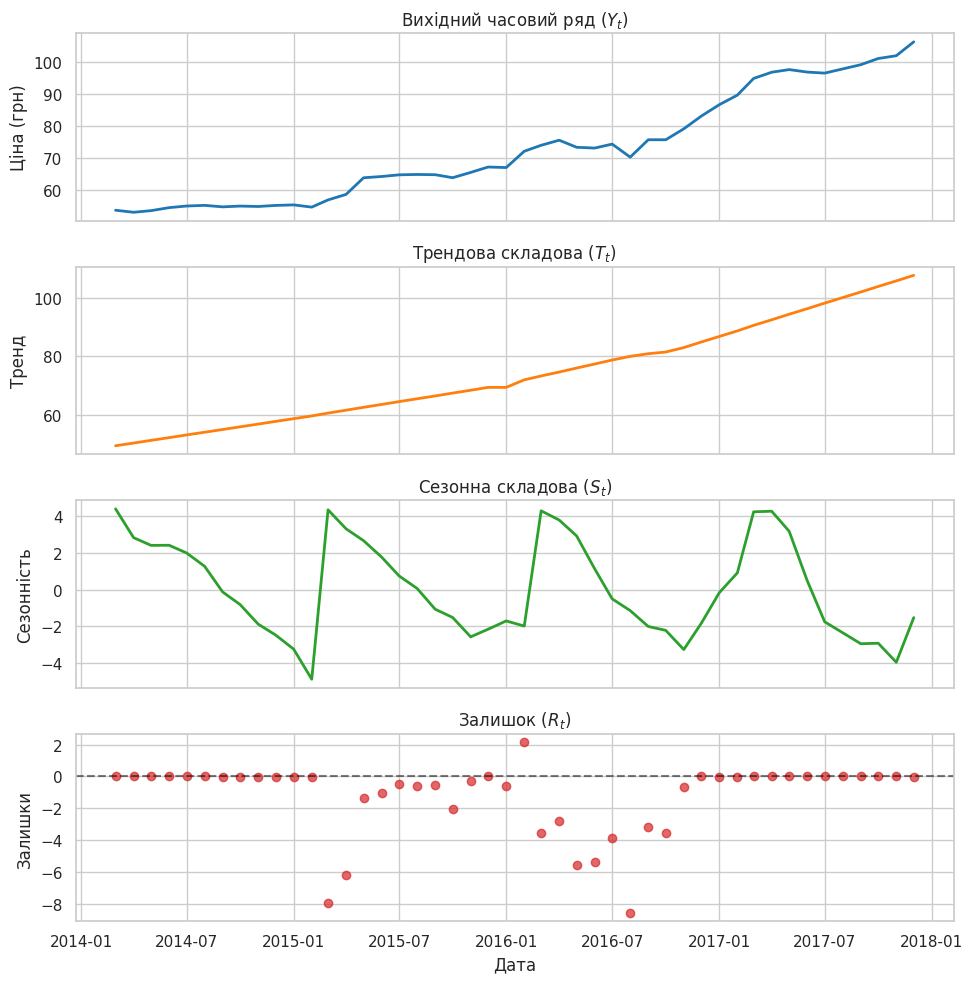

Віджет Seasonal Adjustment (період 12, адитивна модель) розклав ряд на тренд, сезонну складову й залишок. Сезонна складова має однакову форму в усіх роках: максимум ≈ +2.6 навесні, мінімум ≈ −2.5 влітку, розмах ≈ 5 грн. У STL із завдання 4 сезонна складова так само має пік на початку року й спад у другій половині літа, але розмах більший (≈ 9 грн) і форма трохи змінюється по роках. Різниця пояснюється різними алгоритмами: класичне адитивне розкладання дає строго періодичний сезон, STL допускає його зміну. Тренд в обох випадках домінує (зростання з ≈ 52 до ≈ 108 грн), а сезонна складова мала порівняно з ним, що узгоджується з F_S = 0.39 нижче порогу 0.64. Сезонно скоригований ряд збігається з початковим за загальною формою й масштабом, відрізняється лише невеликими коливаннями в межах ±2–3 грн. Залишок в Orange не є чистим шумом (великі відхилення навколо стрибків ціни 2015–2016), як і в STL.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

###Model evaluation з метриками

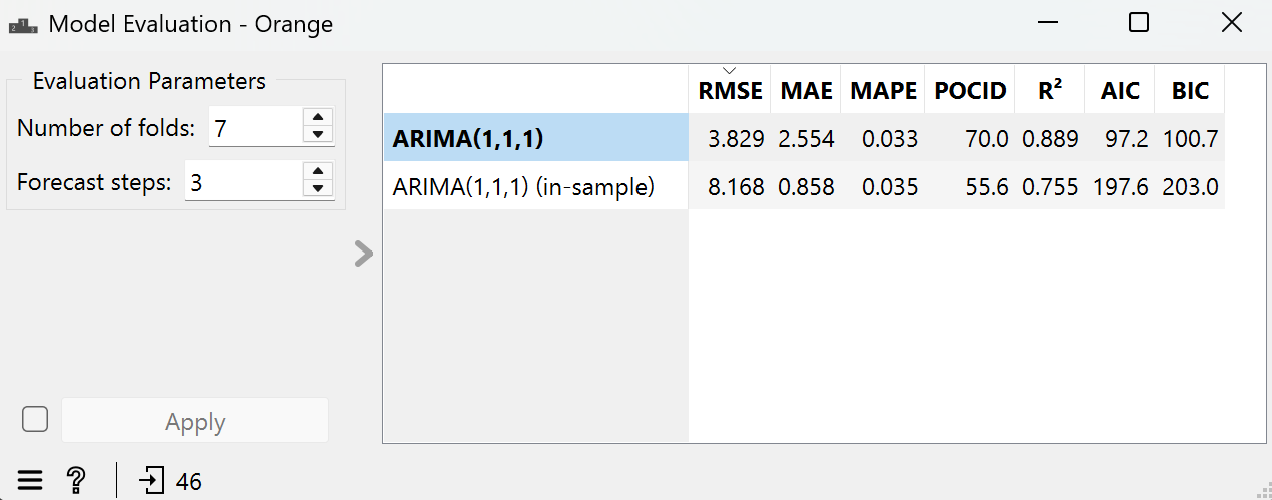

**Висновок до завдання 13:**

Для ARIMA(1,1,1) у Model Evaluation задано 7 фолдів і 3 кроки прогнозу. RMSE = 3.829, MAE = 2.554, MAPE = 0.033. RMSE збігається з Python (3.829), що підтверджує однакові дані, модель і фолди. Рядок in-sample відображає підгонку на всьому ряді, а не прогноз, тому для порівняння з Python його не використовуємо. Типові 20 фолдів × 3 кроки потребують 60 тестових точок, а ряд має 46, тому Orange відмовляється рахувати. (Unexpected error: Supplied time series is too short for this many folds / step size.)

7 фолдів, які перевіряє Orange (нумерація з кінця ряду; ряд має 46 точок):
1. навчання: точки 1–43 (прогноз 44–46)
2. навчання: точки 1–40 (прогноз 41–43)
3. навчання: точки 1–37 (прогноз 38–40)
4. навчання: точки 1–34 (прогноз 35–37)
5. навчання: точки 1–31 (прогноз 32–34)
6. навчання: точки 1–28 (прогноз 29–31)
7. навчання: точки 1–25 (прогноз 26–28)

Орange відрізає від кінця ряду по 3 точки на кожному фолді, тому навчальна частина спадає від 43 до 25 точок. Це ті самі фолди, що й у Python (де вони пронумеровані від найстаршого до найновішого); відрізняється лише порядок

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [ ]:
# Завдання 14. Чому числа не збігаються

a = np.array(all_actual)
p = np.array(all_pred_arima)
e = a - p

rmse_py  = np.sqrt(np.mean(e**2))
mae_med  = np.median(np.abs(e))
mape_or  = np.mean(np.abs(e)) / np.abs(a).mean()

n = 3
a_chunks = [a[i:i+n] for i in range(0, len(a), n)][::-1]
p_chunks = [p[i:i+n] for i in range(0, len(p), n)][::-1]
a_or = np.concatenate(a_chunks)
p_or = np.concatenate(p_chunks)

pocid_py = 100 * np.mean((np.diff(a_or) * np.diff(p_or)) > 0)


print(f"RMSE : {rmse_py:.3f}   (Orange 3.829)")
print(f"MAE  : {mae_med:.3f}   (Orange 2.554)  [звичайне середнє: {np.mean(np.abs(e)):.3f}]")
print(f"MAPE : {mape_or:.3f}   (Orange 0.033)  [звичайний %: {np.mean(np.abs(e/a))*100:.3f}]")
print(f"POCID: {pocid_py:.1f}   (Orange 70.0)")

RMSE : 3.829   (Orange 3.829)
MAE  : 2.554   (Orange 2.554)  [звичайне середнє: 2.941]
MAPE : 0.033   (Orange 0.033)  [звичайний %: 3.398]
POCID: 70.0   (Orange 70.0)


**Висновок до завдання 14:**

Не відповідає назві MAE, бо це медіана (MedAE). MAPE теж відрізняється від звичного: це MAE/середнє, а не середній поточковий відсоток. POCID відрізняється тим, що рахує і стики між фолдами.

RMSE збігся одразу: класична формула й та сама агрегація по всіх прогнозах.

Висновок: перед порівнянням треба перевіряти формулу (середнє чи медіана, поточкова чи відносно середнього), одиниці (частка чи відсоток), спосіб агрегації та порядок/склеювання фолдів.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [ ]:
# Завдання 15. Матриця напрямку зміни

import numpy as np
import pandas as pd

n = 3
a_or = np.concatenate([a[i:i+n] for i in range(0, len(a), n)][::-1])
p_or = np.concatenate([p[i:i+n] for i in range(0, len(p), n)][::-1])

da = np.diff(a_or)
dp = np.diff(p_or)

actual_up = da > 0
pred_up   = dp > 0

tp = np.sum( actual_up &  pred_up)
fn = np.sum( actual_up & ~pred_up)
fp = np.sum(~actual_up &  pred_up)
tn = np.sum(~actual_up & ~pred_up)

cm = pd.DataFrame(
    [[tp, fn], [fp, tn]],
    index=['Факт: зросла', 'Факт: впала'],
    columns=['Прогноз: зросте', 'Прогноз: впаде']
)
print(cm)

total = tp + fn + fp + tn
acc = 100 * (tp + tn) / total
print(f"\nВсього пар (різниць): {total}")
print(f"Частка правильних напрямків: {acc:.1f}%  (POCID Orange: 70.0)")

print(f"\nЯк часто ціна реально зростала: {100*actual_up.mean():.1f}%")
print(f"Як часто модель прогнозувала зростання: {100*pred_up.mean():.1f}%")
print(f"Якщо завжди казати «зросте»: правильно в {100*actual_up.mean():.1f}% випадків")
if (tp + fn) > 0:
    print(f"Із зростань модель впіймала: {100*tp/(tp+fn):.1f}%")
if (tn + fp) > 0:
    print(f"Із падінь модель впіймала: {100*tn/(tn+fp):.1f}%")

              Прогноз: зросте  Прогноз: впаде
Факт: зросла                8               2
Факт: впала                 4               6

Всього пар (різниць): 20
Частка правильних напрямків: 70.0%  (POCID Orange: 70.0)

Як часто ціна реально зростала: 50.0%
Як часто модель прогнозувала зростання: 60.0%
Якщо завжди казати «зросте»: правильно в 50.0% випадків
Із зростань модель впіймала: 80.0%
Із падінь модель впіймала: 60.0%


**Висновок до завдання 15:**

Матриця напрямку побудована на 20 різницях склеєних прогнозів (7 фолдів х 3 кроки, порядок як в Orange). Модель правильно вгадала напрямок у 14 випадках із 20, що дорівнює POCID = 70.0 з Orange.

Помилок 6: у 2 випадках ціна зросла, а модель передбачила падіння, у 4 випадках ціна впала, а модель передбачила зростання. Модель знаходить 80% зростань і 60% падінь, і частіше прогнозує зростання (60%), ніж воно було (50%). У цій вибірці зростання й падіння зустрічаються порівну, тому проста стратегія «завжди зросте» давала б 50%, а модель 70%, тобто напрямок вона вгадує краще за випадковість. Втім, вибірка дуже мала (20 пар), а 6 з 20 різниць стоять на стиках фолдів і порівнюють несусідні місяці, тому 70% є орієнтовною оцінкою; різниця у 20 п.п. на 20 спостереженнях статистично ненадійна, і сказати, що модель точно корисна для рішення «купувати зараз чи чекати», не можна.

Це питання відрізняється від того, на яке відповідають MAE та RMSE: вони міряють, наскільки прогноз далекий від фактичної ціни в гривнях, а матриця лише те, чи вгадано знак зміни. Модель може помилятися на кілька гривень і все одно вгадувати напрямок, і навпаки; для рішення «купувати чи чекати» важливий саме напрямок, а не точна сума.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?
---
1. Сезонності, яка б мала практичне значення, у ряді немає. STL із періодом 12 дав F_S = 0.39, що нижче порогу 0.64, при F_T = 0.98, тобто домінує тренд.
2. Найкращим виявився дрейф (MAE = 2.28, RMSE = 3.11, MAPE = 2.64% на 7 фолдах по 3 кроки), він перевершив наївний прогноз (MAE = 3.07). ARIMA(1,1,1) програла дрейфу (MAE = 2.94, RMSE = 3.83), хоча була трохи кращою за наївний за RMSE і MAE.
3. Сканування за t-статистикою вказало на березень 2017 (t = −16.5, середні рівні 65.5 і 98.8 грн), але довести, що це окрема зміна режиму, а не частина тренду, не можна: перебір багатьох дат і сильна автокореляція роблять p-значення ненадійним, а ряд має сильний тренд (F_T = 0.98). Зовнішнє пояснення також слабке: за даними річної інфляції в Україні (грудень до грудня) 2017 рік (13,7%) мало відрізняється від 2016 (12,4%), а найбільший стрибок припав на 2015 рік (43,3%), тому особливого перелому саме в 2017 інфляція не дає.
4. Однаково названі метрики дали різні числа, бо Orange рахує їх за іншими формулами. Його «MAE» насправді медіана абсолютних помилок, «MAPE» це середня абсолютна помилка, поділена на середнє значення ряду, у частках, а не середній відсоток помилки. POCID рахується по склеєних фолдах у порядку від останнього до першого, тому в нього потрапляють різниці на стиках фолдів.
5. Через короткий ряд (46 точок, менше 4 років) не вдалося надійно встановити сезонність: є лише 3–4 повні цикли, тож F_S і форма сезону оцінюються ненадійно. Не можна було використати типові 20 фолдів (потрібно щонайменше 60 тестових точок), а 7 фолдів дають лише 21 тестове значення, тому різниця між ARIMA і дрейфом статистично не перевірена. Матриця напрямку побудована на 20 парах, тож 70% точності POCID дуже орієнтовні. Тести стаціонарності та t-тест на точку зміни також мають низьку потужність на такій вибірці.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Gemini, Claude |
| Для яких саме завдань |Завдання 3–8, 12, 14-15 |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) |Більша частина коду (графіки, STL, ACF/PACF, тести, базиси, ARIMA, сканування точки зміни,<br> відтворення метрик Orange, матриця напрямку).<br> Пояснення теорії й чернетки деяких з висновків, які я переформулювала своїми словами. |
| Що ви змінили у згенерованому результаті й чому | Прибрала викидний перший залишок ARIMA з графіків. Перейшла з усереднення метрик по фолдах на розрахунок по всіх 21<br> прогнозах, щоб збігалося з Orange. Замінила ШІ-код випадкового поділу на коректний наївний прогноз.<br> Доповнила пункт про точку зміни даними про інфляцію. Налаштування потоку в Orange підбирала сама.|
| Що з отриманого ви **перевірили самостійно** і яким способом | Відтворила RMSE, MAE, MAPE і POCID з Orange у Python до третього знака. Звірила значення ACF з корелограм <br> Orange зі statsmodels. Перевірила, що в Orange ті самі 46 рядків без пропусків. Знайшла в коді додатка формули метрик.|
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Так, наприклад, Gemini неправильно порахував прогноз<br> для випадкового поділу 75/25 (використав середнє замість останнього значення)|

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________